<a href="https://colab.research.google.com/github/Zimeng0815/basecamp-team-26/blob/main/data%20analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
import os

# 1. Check whether the project ZIP file has already been downloaded
if not os.path.exists("/content/project.zip"):
    print("Project has not been downloaded. Downloading now...")
    !wget -q https://github.com/Zimeng0815/basecamp-team-26/archive/refs/heads/main.zip -O /content/project.zip
else:
    print("Project ZIP file already exists. Skipping download.")

# 2. Check whether the project folder has already been extracted
if not os.path.exists("/content/basecamp-team-26-main"):
    print("Project has not been extracted. Extracting now...")
    !unzip -qo /content/project.zip -d /content
else:
    print("Project folder already exists. Skipping extraction.")

# 3. List the contents of the project folder
!ls /content/basecamp-team-26-main


Project ZIP file already exists. Skipping download.
Project folder already exists. Skipping extraction.
ALLSTIMULI     capmit1003.py  Readme.md  Untitled1.ipynb
capmit1003.db  DATASET.md     README.md


In [14]:
import os
import sys
import pandas as pd

# Add the project folder to Python's search path
sys.path.insert(0, '/content/basecamp-team-26-main')

# Import the dataset tools
from capmit1003 import CapMIT1003

# Check whether the database exist
print("Does the database exist?",
      os.path.exists("/content/basecamp-team-26-main/capmit1003.db"))

# Check whether the image folder exist
print("Does the image folder exist?",
      os.path.exists("/content/basecamp-team-26-main/ALLSTIMULI"))


Does the database exist? True
Does the image folder exist? True


# Data Cleaning

In [21]:
# Extract data from the MIT1003 dataset
with CapMIT1003(
    db_path='/content/basecamp-team-26-main/capmit1003.db',
    img_path='/content/basecamp-team-26-main/ALLSTIMULI'
    ) as dataset:

    # Extract captions
    captions = dataset.get_captions()

    # Create an empty list for click data
    all_clicks = []

    # Get click data for each observation
    for obs_uid in captions['obs_uid'].unique():
        clicks = dataset.get_click_path(obs_uid)
        clicks['obs_uid'] = obs_uid
        all_clicks.append(clicks)

    # Combine all click data into one table
    click_data = pd.concat(all_clicks, ignore_index=True)

# Save the extracted data
captions.to_csv('/content/captions.csv', index=False)
click_data.to_csv('/content/clicks.csv', index=False)

In [16]:
print("Captions:", captions.shape)
print("Clicks:", click_data.shape)

display(captions.head())
display(click_data.head())

captions.info()
click_data.info()

Captions: (3848, 6)
Clicks: (25364, 4)


,obs_uid,img_uid,usr_uid,start_time,caption,img_path
0,b47e82fa-a47e-4d80-bace-69dc083346f6,21983b38-d607-4980-91ad-dc665c5da661,bf0ca8f5-aa22-4cd7-ab01-5e7df920b3b6,2023-04-21 20:59:21,A domestic cat sitting in a green field.,mit1003/ALLSTIMULI/i2145018847.jpeg
1,9730f412-da7c-4f1f-b3e4-1e85a8c537f8,a40265c5-2fdf-455d-bd7f-fcd12487459d,bf0ca8f5-aa22-4cd7-ab01-5e7df920b3b6,2023-04-21 21:00:53,People enjoying the sun under palm trees.,mit1003/ALLSTIMULI/i1177391126.jpeg
2,c9749be9-7fdc-46b5-963e-ca698ca7b8de,6b223c5b-bffc-4f68-8d39-b6a53d678558,bf0ca8f5-aa22-4cd7-ab01-5e7df920b3b6,2023-04-21 21:01:30,A brick wall with crumbled stone blocks at its...,mit1003/ALLSTIMULI/i2310011075.jpeg
3,3263f2d1-85e7-456d-9bad-89da523c8318,96869027-7111-4427-b43a-7cbd97c2b3e4,bf0ca8f5-aa22-4cd7-ab01-5e7df920b3b6,2023-04-21 21:02:03,A set of onlookers talking about a sports car ...,mit1003/ALLSTIMULI/i129796908.jpeg
4,b1470a42-cd50-4e13-a4e7-f97d4d12148f,feca3105-4935-4252-81d1-4ee76e1b0797,bf0ca8f5-aa22-4cd7-ab01-5e7df920b3b6,2023-04-21 21:02:46,A rusty train wheel.,mit1003/ALLSTIMULI/i129682290.jpeg


,x,y,time,obs_uid
0,418,204,2023-04-21 20:47:07,b47e82fa-a47e-4d80-bace-69dc083346f6
1,430,488,2023-04-21 20:47:10,b47e82fa-a47e-4d80-bace-69dc083346f6
2,886,146,2023-04-21 20:47:14,b47e82fa-a47e-4d80-bace-69dc083346f6
3,560,118,2023-04-21 21:00:22,9730f412-da7c-4f1f-b3e4-1e85a8c537f8
4,720,606,2023-04-21 21:00:28,9730f412-da7c-4f1f-b3e4-1e85a8c537f8


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3848 entries, 0 to 3847
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   obs_uid     3848 non-null   object
 1   img_uid     3848 non-null   object
 2   usr_uid     3848 non-null   object
 3   start_time  3848 non-null   object
 4   caption     3848 non-null   object
 5   img_path    3848 non-null   object
dtypes: object(6)
memory usage: 180.5+ KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25364 entries, 0 to 25363
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   x        25364 non-null  int64 
 1   y        25364 non-null  int64 
 2   time     25364 non-null  object
 3   obs_uid  25364 non-null  object
dtypes: int64(2), object(2)
memory usage: 792.8+ KB


In [17]:
print("Captions rows:", len(captions))
print("Clicks rows:", len(click_data))

print("Missing values in captions:")
print(captions.isna().sum())

print("Missing values in clicks:")
print(click_data.isna().sum())

print("Duplicated captions:", captions.duplicated().sum())
print("Duplicated clicks:", click_data.duplicated().sum())

print(click_data[['x', 'y']].describe())

Captions rows: 3848
Clicks rows: 25364
Missing values in captions:
obs_uid       0
img_uid       0
usr_uid       0
start_time    0
caption       0
img_path      0
dtype: int64
Missing values in clicks:
x          0
y          0
time       0
obs_uid    0
dtype: int64
Duplicated captions: 0
Duplicated clicks: 100
                  x             y
count  25364.000000  25364.000000
mean     482.150844    406.376360
std      235.355851    182.312889
min       -2.000000      2.000000
25%      292.000000    272.000000
50%      470.000000    396.000000
75%      658.000000    528.000000
max     1022.000000   1016.000000


In [24]:
from PIL import Image

image_sizes = []
missing_images = []

image_folder = '/content/basecamp-team-26-main/ALLSTIMULI'

for path in captions['img_path'].unique():

    filename = os.path.basename(path)
    full_path = os.path.join(image_folder, filename)

    if not os.path.exists(full_path):
        missing_images.append(path)
        continue

    try:
        with Image.open(full_path) as img:
            image_sizes.append({
                'img_path': path,
                'width': img.width,
                'height': img.height
            })
    except Exception:
        missing_images.append(path)

image_info = pd.DataFrame(image_sizes)

print("Images found:", len(image_info))
print("Images missing or unreadable:", len(missing_images))

click_check = pd.merge(
    click_data,
    captions[['obs_uid', 'img_path']],
    on='obs_uid',
    how='left'
)

click_check = pd.merge(
    click_check,
    image_info,
    on='img_path',
    how='left'
)

click_check['in_bounds'] = (
    (click_check['x'] >= 0) &
    (click_check['x'] < click_check['width']) &
    (click_check['y'] >= 0) &
    (click_check['y'] < click_check['height'])
)

print("Total click records:", len(click_check))
print("Valid coordinates:", click_check['in_bounds'].sum())
print("Invalid coordinates:", (~click_check['in_bounds']).sum())

display(click_check[~click_check['in_bounds']].head())


Images found: 1002
Images missing or unreadable: 0
Total click records: 25364
Valid coordinates: 25363
Invalid coordinates: 1


,x,y,time,obs_uid,img_path,width,height,in_bounds
7594,-2,390,2023-04-26 05:46:53,9e624a52-d3d1-42c8-b49b-71ccb8f727c0,/content/basecamp-team-26-main/ALLSTIMULI/i228...,1024,729,False


In [20]:
# Show duplicated click records
duplicate_clicks = click_data[
    click_data.duplicated(keep=False)
]

display(duplicate_clicks.head(20))

,x,y,time,obs_uid
2624,464,468,2023-04-25 10:20:00,1470cc6f-95f9-44fa-a7c3-c9df7b618191
2625,464,468,2023-04-25 10:20:00,1470cc6f-95f9-44fa-a7c3-c9df7b618191
2626,464,468,2023-04-25 10:20:00,1470cc6f-95f9-44fa-a7c3-c9df7b618191
4159,552,332,2023-04-26 18:31:13,38e6e448-c7b3-4074-80f3-5da4c7e507e4
4160,552,332,2023-04-26 18:31:13,38e6e448-c7b3-4074-80f3-5da4c7e507e4
4191,350,440,2023-04-25 11:46:48,9d80570d-6f36-41aa-afcf-fa58feb7ffbd
4192,350,440,2023-04-25 11:46:48,9d80570d-6f36-41aa-afcf-fa58feb7ffbd
4193,810,644,2023-04-25 11:46:49,9d80570d-6f36-41aa-afcf-fa58feb7ffbd
4194,810,644,2023-04-25 11:46:49,9d80570d-6f36-41aa-afcf-fa58feb7ffbd
4196,684,248,2023-04-25 11:46:51,9d80570d-6f36-41aa-afcf-fa58feb7ffbd


In [28]:
# Remove clicks outside image boundaries

clean_clicks = click_check[
    click_check['in_bounds'] == True
]

print("Original clicks:", len(click_data))
print("Cleaned clicks:", len(clean_clicks))
print("Removed clicks:", len(click_data) - len(clean_clicks))

Original clicks: 25364
Cleaned clicks: 25363
Removed clicks: 1


In [29]:
clean_clicks.to_csv("clean_clicks.csv", index=False)

print("Cleaned clicks saved.")

Cleaned clicks saved.


# Visualisation

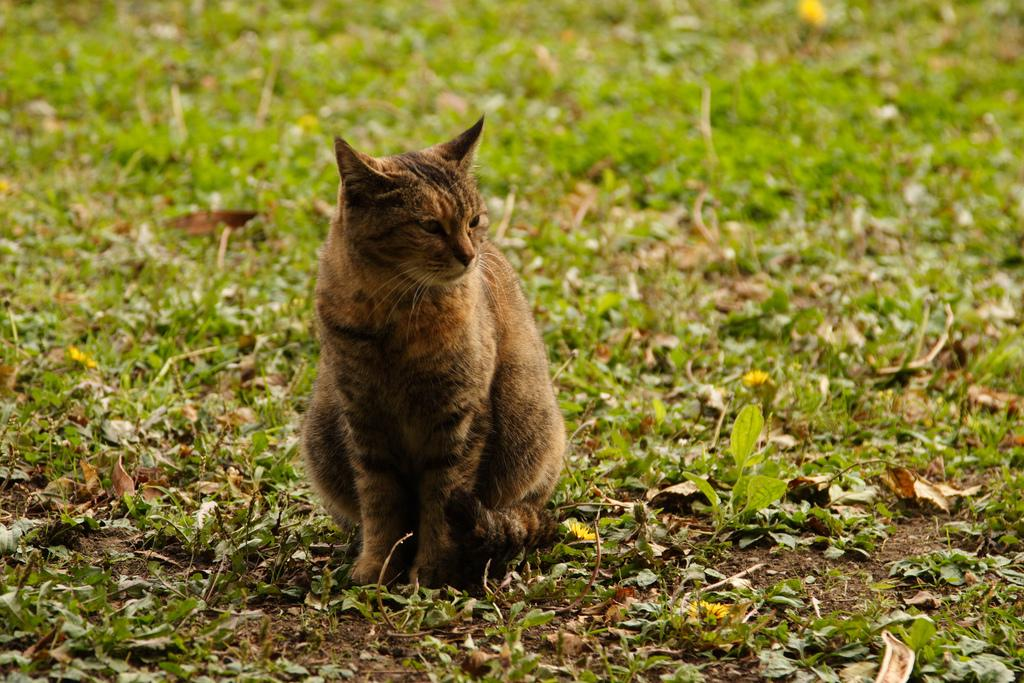

In [30]:
from PIL import Image
from IPython.display import display
display(Image.open("/content/basecamp-team-26-main/ALLSTIMULI/i2145018847.jpeg"))



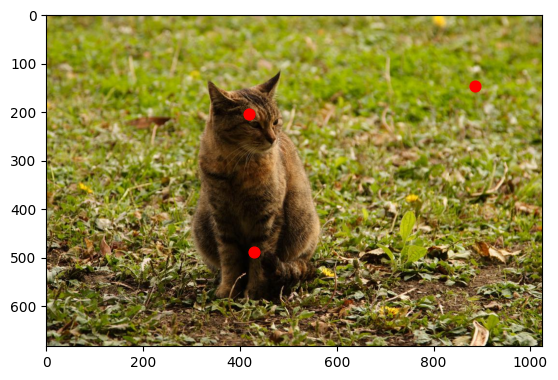

In [31]:
import matplotlib.pyplot as plt

img = Image.open("/content/basecamp-team-26-main/ALLSTIMULI/i2145018847.jpeg")

plt.imshow(img)
plt.scatter([418, 430, 886], [204, 488, 146], color="red", s=60)
plt.xlim(0, img.width)
plt.ylim(img.height, 0)
plt.show()

In [32]:
!find /content/basecamp-team-26-main -type f \( -iname "*.csv" -o -iname "*.tsv" -o -iname "*.json" -o -iname "*.parquet" -o -iname "*.xlsx" \) | head -30

In [33]:
import sqlite3

db_path = "/content/basecamp-team-26-main/capmit1003.db"

with sqlite3.connect(f"file:{db_path}?mode=ro", uri=True) as conn:
    tables = conn.execute("SELECT name FROM sqlite_master WHERE type='table'")
    print([name for (name,) in tables])

['sqlite_sequence', 'captions', 'images', 'clicks']


In [34]:
with sqlite3.connect(f"file:{db_path}?mode=ro", uri=True) as conn:
    for table in ["images", "captions", "clicks"]:
        columns = conn.execute(f"PRAGMA table_info({table})")
        print(table, [column[1] for column in columns])

images ['img_uid', 'img_path']
captions ['obs_uid', 'img_uid', 'usr_uid', 'start_time', 'caption']
clicks ['click_id', 'obs_uid', 'x', 'y', 'click_time']


数据库里的点击记录数： 26
参与者人数： 4


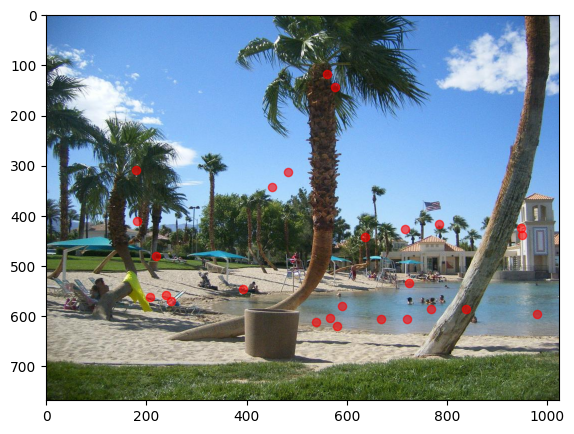

In [35]:
import pandas as pd

filename = "i1177391126.jpeg"

query = """
SELECT clicks.x, clicks.y, captions.usr_uid, clicks.obs_uid
FROM images
JOIN captions ON images.img_uid = captions.img_uid
JOIN clicks ON captions.obs_uid = clicks.obs_uid
WHERE images.img_path LIKE ?
"""

with sqlite3.connect(f"file:{db_path}?mode=ro", uri=True) as conn:
    points = pd.read_sql_query(query, conn, params=(f"%{filename}",))

img = Image.open(f"/content/basecamp-team-26-main/ALLSTIMULI/{filename}")

print("数据库里的点击记录数：", len(points))
print("参与者人数：", points["usr_uid"].nunique())

plt.figure(figsize=(8, 5))
plt.imshow(img)
plt.scatter(points["x"], points["y"], color="red", s=35, alpha=0.6)
plt.xlim(0, img.width)
plt.ylim(img.height, 0)
plt.show()

数据库点击记录数： 26
参与者人数： 4
图内点击记录数： 26


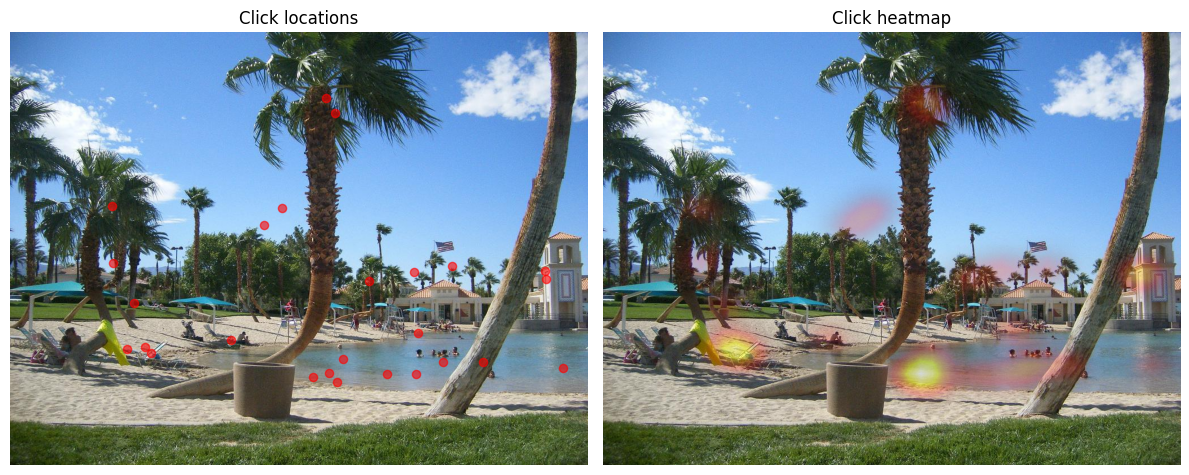

In [36]:
import sqlite3
from contextlib import closing
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from scipy.ndimage import gaussian_filter

# 换图时，只改下面这一行
filename = "i1177391126.jpeg"

project = Path("/content/basecamp-team-26-main")
db_path = project / "capmit1003.db"
image_path = project / "ALLSTIMULI" / filename

# 从数据库找出这张图的点击坐标
query = """
SELECT clicks.x, clicks.y, captions.usr_uid
FROM images
JOIN captions ON images.img_uid = captions.img_uid
JOIN clicks ON captions.obs_uid = clicks.obs_uid
WHERE images.img_path = ? OR images.img_path LIKE ?
"""

with closing(sqlite3.connect(f"file:{db_path}?mode=ro", uri=True)) as conn:
    points = pd.read_sql_query(query, conn, params=(filename, f"%/{filename}"))

with Image.open(image_path) as source:
    img = source.convert("RGB")

# 只绘制落在图片范围内的坐标
valid = points[
    (points["x"] >= 0) & (points["x"] < img.width)
    & (points["y"] >= 0) & (points["y"] < img.height)
]

print("数据库点击记录数：", len(points))
print("参与者人数：", points["usr_uid"].nunique())
print("图内点击记录数：", len(valid))

# 左边画点击点，右边画热力图
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 5))
extent = (0, img.width, img.height, 0)

left.imshow(img, extent=extent)
left.scatter(valid["x"], valid["y"], color="red", s=35, alpha=0.6)
left.set_title("Click locations")

right.imshow(img, extent=extent)
right.set_title("Click heatmap")

if not valid.empty:
    counts, _, _ = np.histogram2d(
        valid["y"], valid["x"],
        bins=50,
        range=[[0, img.height], [0, img.width]]
    )
    heat = gaussian_filter(counts, sigma=1.5)
    right.imshow(
        heat,
        cmap="hot",
        origin="upper",
        interpolation="bilinear",
        extent=extent,
        alpha=0.65 * heat / heat.max()
    )

for ax in (left, right):
    ax.set_xlim(0, img.width)
    ax.set_ylim(img.height, 0)
    ax.axis("off")

plt.tight_layout()
plt.show()

找到 1003 张图片，开始出图。
已处理 50/1003 张


KeyboardInterrupt: 

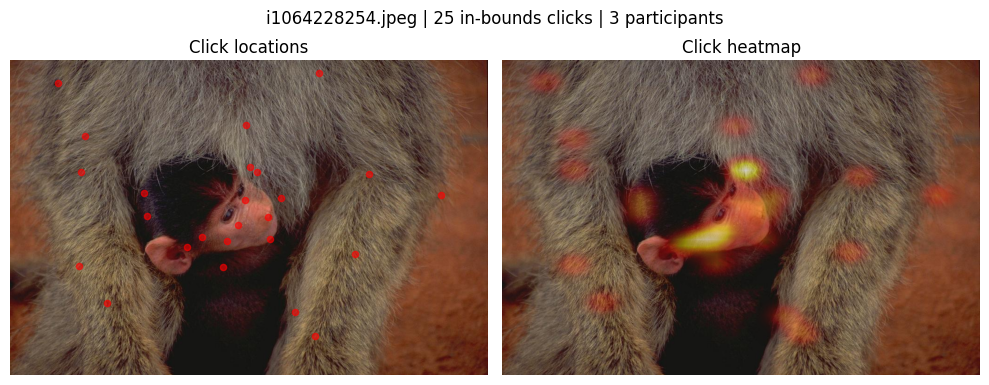

In [37]:
import sqlite3
from contextlib import closing
from io import BytesIO
from pathlib import Path
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from scipy.ndimage import gaussian_filter
from google.colab import files

project = Path("/content/basecamp-team-26-main")
image_folder = project / "ALLSTIMULI"
db_path = project / "capmit1003.db"
zip_path = Path("/content/ALLSTIMULI_click_figures.zip")

# 一次性读取所有图片对应的点击记录
query = """
SELECT images.img_path, clicks.x, clicks.y, captions.usr_uid
FROM images
JOIN captions ON images.img_uid = captions.img_uid
JOIN clicks ON captions.obs_uid = clicks.obs_uid
"""

with closing(sqlite3.connect(f"file:{db_path}?mode=ro", uri=True)) as conn:
    clicks = pd.read_sql_query(query, conn)

clicks["filename"] = clicks["img_path"].str.rsplit("/", n=1).str[-1]
clicks_by_image = dict(iter(clicks.groupby("filename")))

# 找出文件夹里的所有图片
image_paths = sorted(
    path for path in image_folder.iterdir()
    if path.is_file() and path.suffix.lower() in {".jpg", ".jpeg", ".png"}
)

if not image_paths:
    raise FileNotFoundError(f"没有在这个文件夹找到图片：{image_folder}")

print(f"找到 {len(image_paths)} 张图片，开始出图。", flush=True)
without_valid_clicks = 0

with ZipFile(zip_path, "w") as archive:
    for index, image_path in enumerate(image_paths, start=1):
        with Image.open(image_path) as source:
            img = source.convert("RGB")

        points = clicks_by_image.get(image_path.name, clicks.iloc[:0])
        valid = points[
            (points["x"] >= 0) & (points["x"] < img.width)
            & (points["y"] >= 0) & (points["y"] < img.height)
        ]
        extent = (0, img.width, img.height, 0)

        fig, (left, right) = plt.subplots(1, 2, figsize=(10, 4))
        left.imshow(img, extent=extent)
        left.scatter(valid["x"], valid["y"], color="red", s=20, alpha=0.6)
        left.set_title("Click locations")

        right.imshow(img, extent=extent)
        if valid.empty:
            without_valid_clicks += 1
            right.set_title("No in-bounds click records")
        else:
            counts, _, _ = np.histogram2d(
                valid["y"], valid["x"],
                bins=50,
                range=[[0, img.height], [0, img.width]]
            )
            heat = gaussian_filter(counts, sigma=1.5)
            right.imshow(
                heat, cmap="hot", origin="upper",
                interpolation="bilinear", extent=extent,
                alpha=0.65 * heat / heat.max()
            )
            right.set_title("Click heatmap")

        for ax in (left, right):
            ax.set_xlim(0, img.width)
            ax.set_ylim(img.height, 0)
            ax.axis("off")

        fig.suptitle(
            f"{image_path.name} | {len(valid)} in-bounds clicks "
            f"| {valid['usr_uid'].nunique()} participants"
        )
        fig.tight_layout()

        with BytesIO() as buffer:
            fig.savefig(buffer, format="png", dpi=100)
            archive.writestr(f"{image_path.name}_clicks.png", buffer.getvalue())
        plt.close(fig)

        if index % 50 == 0 or index == len(image_paths):
            print(f"已处理 {index}/{len(image_paths)} 张", flush=True)

print(f"完成。没有图内点击记录的图片：{without_valid_clicks} 张。")
files.download(str(zip_path))

# Charts

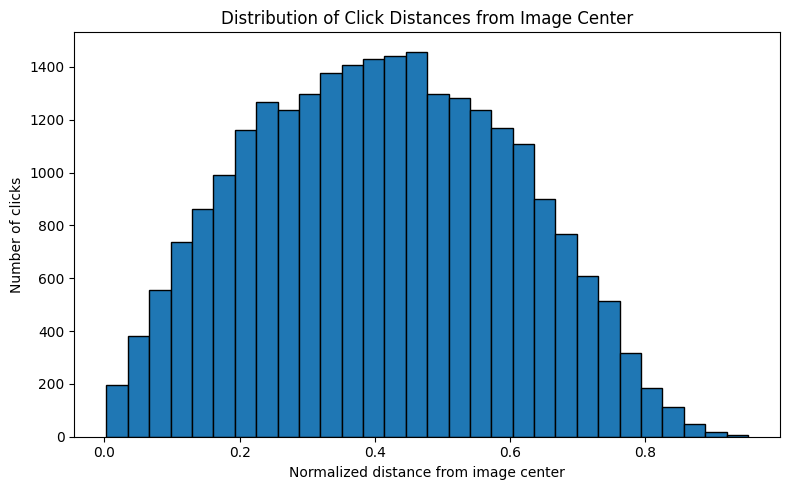

In [38]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 读取清理后的点击数据
df = pd.read_csv("/content/clean_clicks.csv")

# 计算每张图片的中心
center_x = df["width"] / 2
center_y = df["height"] / 2

# 计算每个点击点到图片中心的欧氏距离
df["center_distance"] = np.sqrt(
    (df["x"] - center_x) ** 2 +
    (df["y"] - center_y) ** 2
)

# 计算归一化距离
max_distance = np.sqrt(
    center_x ** 2 + center_y ** 2
)

df["normalized_distance"] = (
    df["center_distance"] / max_distance
)

# 绘制归一化距离直方图
plt.figure(figsize=(8, 5))

plt.hist(
    df["normalized_distance"],
    bins=30,
    edgecolor="black"
)

plt.xlabel("Normalized distance from image center")
plt.ylabel("Number of clicks")
plt.title("Distribution of Click Distances from Image Center")

plt.tight_layout()
plt.show()


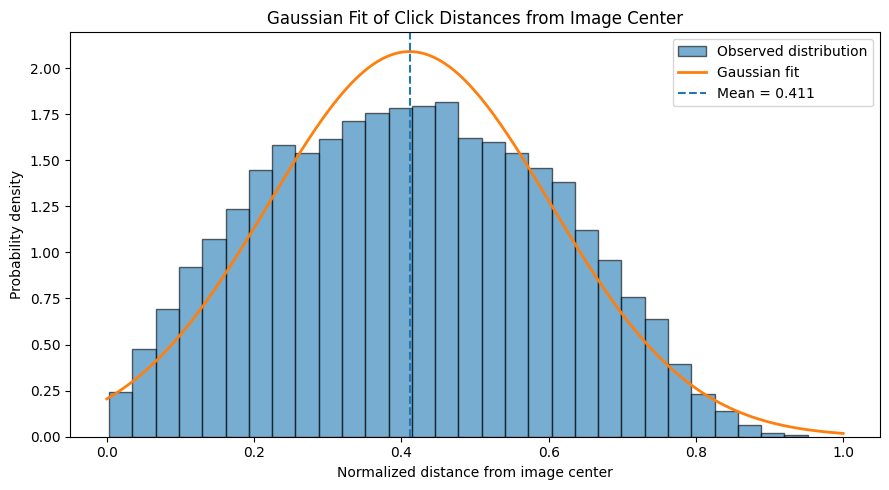

Mean: 0.4112
Standard deviation: 0.1909


In [39]:

from scipy.stats import norm
import numpy as np
import matplotlib.pyplot as plt

# 提取归一化距离，排除无效值
distances = df["normalized_distance"].dropna()

# 计算均值和标准差
mean = distances.mean()
std = distances.std()

# 绘制直方图（density=True，使其可以与概率密度曲线比较）
plt.figure(figsize=(9, 5))

plt.hist(
    distances,
    bins=30,
    density=True,
    alpha=0.6,
    edgecolor="black",
    label="Observed distribution"
)

# 拟合高斯分布
x = np.linspace(0, 1, 300)
y = norm.pdf(x, mean, std)

plt.plot(
    x, y,
    linewidth=2,
    label="Gaussian fit"
)

# 标记均值
plt.axvline(
    mean,
    linestyle="--",
    linewidth=1.5,
    label=f"Mean = {mean:.3f}"
)

plt.xlabel("Normalized distance from image center")
plt.ylabel("Probability density")
plt.title("Gaussian Fit of Click Distances from Image Center")

plt.legend()
plt.tight_layout()
plt.show()

print(f"Mean: {mean:.4f}")
print(f"Standard deviation: {std:.4f}")
